# Akuisisi Data Akomodasi Kecamatan Kintamani
BIFP-243 Akuisisi dan Manajemen Data. Jalankan semua sel dari atas ke bawah.
Sumber: © OpenStreetMap contributors (ODbL 1.0).

In [1]:
# 1. Mount Google Drive dan buat struktur folder (disimpan di Drive agar tidak hilang)
import os
from pathlib import Path

NIM = "2501010369"

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path(f"/content/drive/MyDrive/akomodasi_kintamani_{NIM}")
except ImportError:
    BASE = Path(f"akomodasi_kintamani_{NIM}")  # dijalankan di luar Colab

RAW = BASE / "data" / "raw"
INTERIM = BASE / "data" / "interim"
DOCS = BASE / "docs"
REPORTS = BASE / "reports"
NOTEBOOKS = BASE / "notebooks"

for p in [RAW, INTERIM, DOCS, REPORTS, NOTEBOOKS]:
    p.mkdir(parents=True, exist_ok=True)

print("Struktur folder proyek:")
for akar, _, _ in os.walk(BASE):
    level = str(akar).replace(str(BASE), "").count(os.sep)
    print("    " * level + os.path.basename(akar) + "/")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Struktur folder proyek:
akomodasi_kintamani_2501010369/
    data/
        raw/
        interim/
    docs/
    reports/
    notebooks/


In [2]:

NAMA = "Katarina Gita Candranurani"
EMAIL = "nuranynurany16@gmail.com"

URL = "https://overpass-api.de/api/interpreter"
HEADERS = {"User-Agent": f"INSTIKI-BIFP243-Praktikum/1.0 ({EMAIL})"}

assert "ISI" not in NAMA, "Isi NAMA dulu!"
print("Konfigurasi siap untuk:", NAMA, NIM)

Konfigurasi siap untuk: Katarina Gita Candranurani 2501010369


In [3]:

QUERY = """
[out:json][timeout:90];
area["name"="Kintamani"]["boundary"="administrative"]["admin_level"="6"]->.kec;
nwr["tourism"~"^(hotel|guest_house|hostel|motel|apartment|chalet)$"](area.kec);
out center tags;
""".strip()

(DOCS / "query_overpass.txt").write_text(QUERY + "\n", encoding="utf-8")
print("Query disimpan di:", DOCS / "query_overpass.txt")
print(QUERY)

Query disimpan di: /content/drive/MyDrive/akomodasi_kintamani_2501010369/docs/query_overpass.txt
[out:json][timeout:90];
area["name"="Kintamani"]["boundary"="administrative"]["admin_level"="6"]->.kec;
nwr["tourism"~"^(hotel|guest_house|hostel|motel|apartment|chalet)$"](area.kec);
out center tags;


In [4]:

import json, time
import requests
from datetime import datetime, timezone
from collections import Counter

LOG = []

def ambil_overpass(query, maks_percobaan=4, jeda=5):
    for percobaan in range(1, maks_percobaan + 1):
        try:
            r = requests.post(URL, data={"data": query}, headers=HEADERS, timeout=120)
            if r.status_code == 200:
                LOG.append(f"[percobaan {percobaan}] status 200 (berhasil)")
                return r.json()
            pesan = f"[percobaan {percobaan}] status {r.status_code}, tunggu {jeda}s"
        except (requests.Timeout, requests.ConnectionError) as e:
            pesan = f"[percobaan {percobaan}] {type(e).__name__}, tunggu {jeda}s"
        print(pesan)
        LOG.append(pesan)
        if percobaan < maks_percobaan:
            time.sleep(jeda)
            jeda *= 2
    raise RuntimeError("Gagal mengambil data dari Overpass")

file_raw_ada = sorted(RAW.glob("osm_akomodasi_kintamani_*.json"))

if file_raw_ada:
    raw_path = file_raw_ada[-1]
    print("Berkas mentah sudah ada, dipakai ulang:", raw_path.name)
    data = json.loads(raw_path.read_text(encoding="utf-8"))
else:
    print("Mengambil data dari Overpass...")
    data = ambil_overpass(QUERY)
    stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
    raw_path = RAW / f"osm_akomodasi_kintamani_{stamp}.json"
    raw_path.write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")
    (DOCS / "log_akuisisi.txt").write_text("\n".join(LOG) + "\n", encoding="utf-8")
    print("Respons mentah disimpan:", raw_path.name)

elements = data["elements"]
print("Jumlah elemen:", len(elements))
if len(elements) == 0:
    raise ValueError("Data kosong. Periksa query dan batas wilayah.")

print("\nJumlah per jenis:")
for j, n in Counter(e.get("tags", {}).get("tourism") for e in elements).items():
    print(f"  {j}: {n}")

Berkas mentah sudah ada, dipakai ulang: osm_akomodasi_kintamani_20261110_121248.json
Jumlah elemen: 32

Jumlah per jenis:
  hotel: 16
  guest_house: 9
  hostel: 4
  chalet: 2
  motel: 1


In [7]:
import hashlib, json
from datetime import datetime, timezone
from pathlib import Path

# 1. Cek variabel dasar (tidak bisa dipulihkan otomatis)
for nama_var in ["URL", "QUERY", "NAMA", "NIM"]:
    if nama_var not in globals():
        raise NameError(
            f"'{nama_var}' belum didefinisikan. Jalankan sel pengaturan di atas "
            "(Runtime > Run before)."
        )

# 2. Pulihkan raw_path jika hilang: ambil berkas .json terbaru
if "raw_path" not in globals():
    kandidat = sorted(
        list(Path("data").rglob("*.json")) + list(Path(".").glob("*.json")),
        key=lambda p: p.stat().st_mtime,
    )
    if not kandidat:
        raise FileNotFoundError(
            "Berkas mentah tidak ditemukan. Jalankan ulang sel akuisisi data."
        )
    raw_path = kandidat[-1]
    print(f"[peringatan] raw_path dipulihkan dari berkas terbaru: {raw_path}")

# 3. Pulihkan data jika hilang
if "data" not in globals():
    data = json.loads(raw_path.read_text(encoding="utf-8"))

# 4. Pulihkan waktu_akuisisi jika hilang (pakai waktu modifikasi berkas, UTC)
if "waktu_akuisisi" not in globals():
    waktu_akuisisi = datetime.fromtimestamp(raw_path.stat().st_mtime, tz=timezone.utc)
    print("[peringatan] waktu_akuisisi diperkirakan dari waktu modifikasi berkas.")
elif waktu_akuisisi.tzinfo is None:
    waktu_akuisisi = waktu_akuisisi.replace(tzinfo=timezone.utc)

# 5. Validasi data
assert len(data["elements"]) > 0, "Data kosong, periksa kueri Overpass"

# 6. Buat provenance
Path("docs").mkdir(exist_ok=True)
raw_bytes = raw_path.read_bytes()

provenance = {
    "url_endpoint": URL,
    "query": QUERY.strip(),
    "waktu_akuisisi_utc": waktu_akuisisi.astimezone(timezone.utc).isoformat(),
    "versi_data_osm": data.get("osm3s", {}).get("timestamp_osm_base"),
    "jumlah_elemen": len(data["elements"]),
    "nama_file_mentah": raw_path.name,
    "hash_md5": hashlib.md5(raw_bytes).hexdigest(),
    "hash_sha256": hashlib.sha256(raw_bytes).hexdigest(),
    "lisensi": "Open Database License (ODbL)",
    "atribusi": "© OpenStreetMap contributors",
    "nama_pengambil": NAMA,
    "nim_pengambil": NIM,
}

Path("docs/provenance.json").write_text(
    json.dumps(provenance, ensure_ascii=False, indent=2), encoding="utf-8")

print("Provenance berhasil dibuat: docs/provenance.json")
print(json.dumps({k: v for k, v in provenance.items() if k != "query"},
                 ensure_ascii=False, indent=2))

[peringatan] waktu_akuisisi diperkirakan dari waktu modifikasi berkas.
Provenance berhasil dibuat: docs/provenance.json
{
  "url_endpoint": "https://overpass-api.de/api/interpreter",
  "waktu_akuisisi_utc": "2026-11-10T12:12:48+00:00",
  "versi_data_osm": "2026-11-10T12:11:22Z",
  "jumlah_elemen": 32,
  "nama_file_mentah": "osm_akomodasi_kintamani_20261110_121248.json",
  "hash_md5": "fb96d6de280ea9e879e1fdd9182124e9",
  "hash_sha256": "3d8f621964ae2c6e2928323bfe7c8e561a880e9f6edb52494cf477a9de59ef04",
  "lisensi": "Open Database License (ODbL)",
  "atribusi": "© OpenStreetMap contributors",
  "nama_pengambil": "Katarina Gita Candranurani",
  "nim_pengambil": "2501010369"
}


In [8]:

import pandas as pd

def ratakan(elements):
    baris = []
    for e in elements:
        tg = e.get("tags", {})
        pusat = e.get("center", e)  # node: lat/lon langsung; way: di center
        baris.append({
            "osm_type": e["type"],
            "osm_id": e["id"],
            "nama": tg.get("name"),
            "jenis": tg.get("tourism"),
            "lat": pusat.get("lat"),
            "lon": pusat.get("lon"),
            "desa": tg.get("addr:village"),
            "bintang": tg.get("stars"),
            "jumlah_kamar": tg.get("rooms"),
            "website": tg.get("website") or tg.get("contact:website"),
            "url_osm": f"https://www.openstreetmap.org/{e['type']}/{e['id']}",
        })
    return pd.DataFrame(baris)

akomodasi = ratakan(elements)
assert len(akomodasi) == len(elements), "Ada elemen yang hilang!"

file_csv = INTERIM / "akomodasi_kintamani.csv"
akomodasi.to_csv(file_csv, index=False, encoding="utf-8-sig")

print("Elemen JSON :", len(elements))
print("Baris CSV   :", len(akomodasi))
print("Kolom       :", list(akomodasi.columns))
print("Tanpa nama  :", akomodasi["nama"].isna().sum())
print("Disimpan di :", file_csv)
display(akomodasi.head(10))

Elemen JSON : 32
Baris CSV   : 32
Kolom       : ['osm_type', 'osm_id', 'nama', 'jenis', 'lat', 'lon', 'desa', 'bintang', 'jumlah_kamar', 'website', 'url_osm']
Tanpa nama  : 1
Disimpan di : /content/drive/MyDrive/akomodasi_kintamani_2501010369/data/interim/akomodasi_kintamani.csv


,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,None,None,None,http://lakeviewbali.com/en/,https://www.openstreetmap.org/node/1977779907
1,node,2107226701,Arlina,guest_house,-8.249815,115.398465,None,None,None,None,https://www.openstreetmap.org/node/2107226701
2,node,2107227001,Toya Devasya Resort,hotel,-8.250164,115.399798,None,None,None,None,https://www.openstreetmap.org/node/2107227001
3,node,4150326329,Guesthouse,hotel,-8.281456,115.362223,None,None,None,None,https://www.openstreetmap.org/node/4150326329
4,node,4297310696,The Cave Hotel,hotel,-8.280748,115.362048,None,2,5,None,https://www.openstreetmap.org/node/4297310696
5,node,4401927990,batur montáin view,hotel,-8.260754,115.338771,None,None,None,None,https://www.openstreetmap.org/node/4401927990
6,node,4863479822,Miranda Homestay & Restaurant,guest_house,-8.246313,115.327402,None,None,None,None,https://www.openstreetmap.org/node/4863479822
7,node,4905949623,Lava Stone Hostel,hostel,-8.250325,115.397136,None,None,None,None,https://www.openstreetmap.org/node/4905949623
8,node,5065920543,The Volcania Guesthouse,hotel,-8.283796,115.365242,None,None,None,None,https://www.openstreetmap.org/node/5065920543
9,node,5175562421,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,None,None,None,None,https://www.openstreetmap.org/node/5175562421


In [9]:
import numpy as np

df = pd.read_csv(file_csv, dtype={"bintang": str, "jumlah_kamar": str})
kolom_dataset = list(df.columns)

n_dup = int(df.duplicated(subset=["osm_type", "osm_id"]).sum())
nama_kosong = df["nama"].isna() | (df["nama"].astype(str).str.strip() == "")
koor_kosong = df["lat"].isna() | df["lon"].isna()
koor_invalid = (~koor_kosong) & (~df["lat"].between(-90, 90) | ~df["lon"].between(-180, 180))

def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

# kolom bantu hanya di salinan, tidak masuk dataset
cek = df.copy()
cek["jarak_ke_pusat_km"] = haversine_km(cek["lat"], cek["lon"], cek["lat"].median(), cek["lon"].median()).round(2)
JARAK_BATAS_KM = 10
jauh = cek["jarak_ke_pusat_km"] > JARAK_BATAS_KM

nama_str = cek["nama"].fillna("").str.lower()
nama_ganda = cek["nama"].notna() & cek["nama"].duplicated(keep=False)
nama_curiga = nama_str.str.startswith("entrance") | nama_str.str.contains("real location") | nama_ganda

kosong = pd.DataFrame({
    "jumlah_kosong": df.isna().sum(),
    "persen_kosong": (df.isna().mean() * 100).round(2),
})

laporan = pd.DataFrame({
    "pemeriksaan": [
        "Jumlah seluruh data",
        "Duplikat (osm_type + osm_id)",
        "Nama kosong",
        "Koordinat kosong",
        "Koordinat tidak valid",
        f"Titik > {JARAK_BATAS_KM} km dari pusat sebaran",
        "Nama mencurigakan (entrance / real location / nama ganda)",
        "Kolom desa kosong",
        "Kolom bintang kosong",
    ],
    "jumlah": [len(df), n_dup, int(nama_kosong.sum()), int(koor_kosong.sum()), int(koor_invalid.sum()),
               int(jauh.sum()), int(nama_curiga.sum()), int(df["desa"].isna().sum()), int(df["bintang"].isna().sum())],
    "keputusan": [
        "-",
        "Tidak ada duplikat; tidak ada yang dihapus",
        "Dipertahankan (dihitung jumlahnya sesuai instruksi)",
        "Tidak ada",
        "Tidak ada",
        "Dipertahankan; WAJIB cek url_osm: apakah masih di Kecamatan Kintamani (isi hasilnya di laporan)",
        "Dipertahankan, tidak dihapus diam-diam; WAJIB cek url_osm (objek pintu masuk / lokasi ganda / nama sama)",
        "Dipertahankan; tag addr:village jarang diisi relawan, ringkasan per desa tidak bisa dibuat",
        "Dipertahankan; kolom hampir selalu kosong, dibiarkan bertipe teks",
    ],
})
laporan.to_csv(DOCS / "pemeriksaan_kualitas.csv", index=False)
kosong.to_csv(DOCS / "pemeriksaan_kolom_kosong.csv")
cek.loc[jauh | nama_curiga | nama_kosong,
        ["osm_type", "osm_id", "nama", "jenis", "lat", "lon", "jarak_ke_pusat_km", "url_osm"]] \
   .to_csv(DOCS / "temuan_perlu_dicek.csv", index=False)

display(laporan)
print("\nKolom kosong:")
display(kosong)
print("\nTemuan yang perlu dicek manual di OpenStreetMap (juga disimpan di docs/temuan_perlu_dicek.csv):")
display(cek.loc[jauh | nama_curiga | nama_kosong,
                ["osm_id", "nama", "jenis", "lat", "lon", "jarak_ke_pusat_km", "url_osm"]])

,pemeriksaan,jumlah,keputusan
0,Jumlah seluruh data,32,-
1,Duplikat (osm_type + osm_id),0,Tidak ada duplikat; tidak ada yang dihapus
2,Nama kosong,1,Dipertahankan (dihitung jumlahnya sesuai instr...
3,Koordinat kosong,0,Tidak ada
4,Koordinat tidak valid,0,Tidak ada
5,Titik > 10 km dari pusat sebaran,1,Dipertahankan; WAJIB cek url_osm: apakah masih...
6,Nama mencurigakan (entrance / real location / ...,4,"Dipertahankan, tidak dihapus diam-diam; WAJIB ..."
7,Kolom desa kosong,32,Dipertahankan; tag addr:village jarang diisi r...
8,Kolom bintang kosong,31,"Dipertahankan; kolom hampir selalu kosong, dib..."



Kolom kosong:


,jumlah_kosong,persen_kosong
osm_type,0,0.00
osm_id,0,0.00
nama,1,3.12
jenis,0,0.00
lat,0,0.00
lon,0,0.00
desa,32,100.00
bintang,31,96.88
jumlah_kamar,30,93.75
website,30,93.75



Temuan yang perlu dicek manual di OpenStreetMap (juga disimpan di docs/temuan_perlu_dicek.csv):


,osm_id,nama,jenis,lat,lon,jarak_ke_pusat_km,url_osm
9,5175562421,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,3.03,https://www.openstreetmap.org/node/5175562421
11,5479745921,Hut,chalet,-8.242432,115.387471,1.23,https://www.openstreetmap.org/node/5479745921
12,5479746121,Hut,chalet,-8.242693,115.387587,1.21,https://www.openstreetmap.org/node/5479746121
20,7216701986,Volcano hostel - real location,hostel,-8.225994,115.400760,2.63,https://www.openstreetmap.org/node/7216701986
31,1181397894,NaN,motel,-8.223372,115.254582,15.86,https://www.openstreetmap.org/way/1181397894


In [10]:
# 8. Ringkasan per jenis dan per desa
per_jenis = df["jenis"].value_counts().rename_axis("jenis").reset_index(name="jumlah")
per_desa = (df["desa"].fillna("(tidak tercatat)")
              .value_counts().rename_axis("desa").reset_index(name="jumlah"))

per_jenis.to_csv(DOCS / "ringkasan_per_jenis.csv", index=False)
per_desa.to_csv(DOCS / "ringkasan_per_desa.csv", index=False)

print("Per jenis:")
display(per_jenis)
print("Per desa (kolom desa kosong karena tag addr:village jarang diisi relawan):")
display(per_desa)

Per jenis:


,jenis,jumlah
0,hotel,16
1,guest_house,9
2,hostel,4
3,chalet,2
4,motel,1


Per desa (kolom desa kosong karena tag addr:village jarang diisi relawan):


,desa,jumlah
0,(tidak tercatat),32


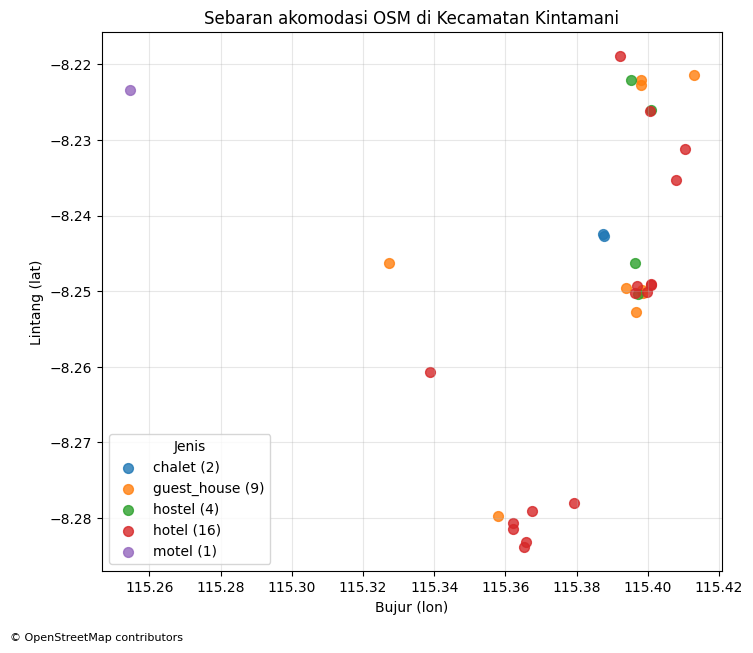

Peta disimpan: /content/drive/MyDrive/akomodasi_kintamani_2501010369/reports/peta_sebaran.png


In [11]:
# 9. Peta sebaran sederhana
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 7))
for jenis, g in df.groupby("jenis"):
    ax.scatter(g["lon"], g["lat"], label=f"{jenis} ({len(g)})", s=50, alpha=0.8)

ax.set_xlabel("Bujur (lon)")
ax.set_ylabel("Lintang (lat)")
ax.set_title("Sebaran akomodasi OSM di Kecamatan Kintamani")
ax.legend(title="Jenis")
ax.grid(alpha=0.3)
fig.text(0.01, 0.01, "\u00a9 OpenStreetMap contributors", fontsize=8)

peta_path = REPORTS / "peta_sebaran.png"
fig.savefig(peta_path, dpi=150, bbox_inches="tight")
plt.show()
print("Peta disimpan:", peta_path)

In [13]:
import pandas as pd
from datetime import datetime
from pathlib import Path

# 10. Perbandingan dengan BPS  -->  ISI sumber_bps DENGAN PUBLIKASI BPS ASLI
jumlah_bps  = 118
tahun_bps   = 2023
sumber_bps  = "ISI: judul publikasi BPS, tahun terbit, nomor tabel/halaman"
tingkat_bps = "kecamatan"   # ubah jika angka per kabupaten, dan jelaskan di laporan

if "ISI" in sumber_bps:
    print("PERINGATAN: sumber_bps belum diisi. Catat publikasi BPS asal angka",
          jumlah_bps, "sebelum mengumpulkan laporan.")

# Pastikan DOCS tersedia
if "DOCS" not in globals():
    DOCS = Path("docs")
DOCS.mkdir(exist_ok=True)

# Tanggal akuisisi (aman untuk datetime maupun string)
if isinstance(waktu_akuisisi, datetime):
    tanggal_akuisisi = waktu_akuisisi.strftime("%Y-%m-%d")
    tahun_osm = waktu_akuisisi.year
else:
    tanggal_akuisisi = str(waktu_akuisisi)[:10]
    tahun_osm = int(tanggal_akuisisi[:4])

jumlah_osm = len(df)
assert jumlah_bps > 0, "jumlah_bps harus lebih dari 0"
kelengkapan = round(jumlah_osm / jumlah_bps * 100, 2)

perbandingan = pd.DataFrame({
    "sumber": ["OpenStreetMap (Overpass API)", "BPS"],
    "tahun_data": [tahun_osm, tahun_bps],
    "jumlah_akomodasi": [jumlah_osm, jumlah_bps],
    "tingkat_wilayah": ["kecamatan (admin_level 6)", tingkat_bps],
    "keterangan": [f"Diambil {tanggal_akuisisi}", sumber_bps],
    "persentase_kelengkapan_osm": [kelengkapan, None],
})

perbandingan.to_csv(DOCS / "perbandingan_bps.csv", index=False)
print(perbandingan.to_string(index=False))

PERINGATAN: sumber_bps belum diisi. Catat publikasi BPS asal angka 118 sebelum mengumpulkan laporan.
                      sumber  tahun_data  jumlah_akomodasi           tingkat_wilayah                                                  keterangan  persentase_kelengkapan_osm
OpenStreetMap (Overpass API)        2026                32 kecamatan (admin_level 6)                                          Diambil 2026-11-10                       27.12
                         BPS        2023               118                 kecamatan ISI: judul publikasi BPS, tahun terbit, nomor tabel/halaman                         NaN


In [14]:
# 11. Verifikasi manual 10 sampel (ISI MANUAL lewat url_osm / situs resmi / peta; jangan scraping OTA/Google Maps)
file_verif = DOCS / "Verifikasi_10_sempel.csv"

# Jika file lama berformat lama (kolom verifikasi_nama dst.), cadangkan lalu buat ulang
if file_verif.exists():
    lama = pd.read_csv(file_verif)
    if "nama_benar" not in lama.columns:
        file_verif.rename(DOCS / "verifikasi_10_sampel_format_lama.bak")
        print("Format lama dicadangkan; dibuat ulang dengan format baru.")

if file_verif.exists():
    print("File verifikasi sudah ada, TIDAK ditimpa (isian manual aman).")
else:
    sampel = df.sample(n=min(10, len(df)), random_state=42).copy()
    verif = sampel[["osm_type", "osm_id", "nama", "jenis", "lat", "lon", "url_osm"]].copy()
    verif["nama_benar"] = ""         # isi: Ya / Tidak / Tidak bisa dicek
    verif["jenis_benar"] = ""        # isi: Ya / Tidak / Tidak bisa dicek
    verif["lokasi_benar"] = ""       # isi: Ya / Tidak / Tidak bisa dicek
    verif["sumber_verifikasi"] = ""  # mis. situs resmi / OSM / peta
    verif["catatan"] = ""
    verif.to_csv(file_verif, index=False)
    print("File verifikasi dibuat:", file_verif)

verif_df = pd.read_csv(file_verif)
terisi = int(verif_df[["nama_benar", "jenis_benar", "lokasi_benar"]].notna().all(axis=1).sum())
print(f"Sampel yang sudah diverifikasi: {terisi} dari {len(verif_df)}")
display(verif_df)

File verifikasi sudah ada, TIDAK ditimpa (isian manual aman).
Sampel yang sudah diverifikasi: 10 dari 10


,osm_type,osm_id,nama,jenis,lat,lon,url_osm,nama_benar,jenis_benar,lokasi_benar,sumber_verifikasi,catatan
0,node,13068182153,Batur Sunrise Guesthouse,hotel,-82.490.202,115.400.863,https://www.openstreetmap.org/node/13068182153,Ya,Ya,Ya,Google Maps satelit (dilihat manual),ada bangunan dititik
1,node,6451134585,Caldera,hotel,-82.791.389,1.153.673.639,https://www.openstreetmap.org/node/6451134585,Ya,Ya,Ya,Google Maps satelit (dilihat manual),ada bangunan dititik
2,node,9769685089,Bunbulan Panorama Villas,guest_house,-82.227.355,1.153.979.713,https://www.openstreetmap.org/node/9769685089,Ya,Ya,Ya,Google Maps satelit (dilihat manual),ada bangunan dititik
3,node,7058054537,Segara Hotel,hotel,-82.780.864,1.153.791.336,https://www.openstreetmap.org/node/7058054537,Ya,Ya,Ya,Google Maps satelit (dilihat manual),ada bangunan dititik
4,node,5065920543,The Volcania Guesthouse,hotel,-82.837.958,1.153.652.416,https://www.openstreetmap.org/node/5065920543,Ya,Ya,Ya,Google Maps satelit (dilihat manual),ada bangunan dititik
5,node,5175562421,Entrance to: Bunbulan Hill Hostel,hostel,-82.220.144,1.153.953.491,https://www.openstreetmap.org/node/5175562421,Tidak,Tidak bisa dicek,Ya,Google Maps satelit (dilihat manual),Di Google kategori Biro Wisata; di OSM hostel;...
6,node,13284479326,Lava Bali and Hot Spring,hotel,-82.503.106,1.153.963.742,https://www.openstreetmap.org/node/13284479326,Ya,Ya,Ya,Google Maps satelit (dilihat manual),Bungalow terlihat di titik OSM; pin Google ± 7...
7,node,9778735917,Villa Jempana,hotel,-82.311.582,1.154.105.557,https://www.openstreetmap.org/node/9778735917,Ya,Ya,Ya,Google Maps satelit (dilihat manual),Pin Google ± beberapa puluh meter dari titik O...
8,node,5479746121,Hut,chalet,-82.426.933,115.387.587,https://www.openstreetmap.org/node/5479746121,Tidak bisa dicek,Tidak bisa dicek,tidak bisa dicek,OSM (tag dan peta); Google Maps Street View 20...,Nama generik ‘Hut’; titik berada di jalur pend...
9,node,1977779907,The Lakeview Hotel Bali,hotel,-82.831.398,1.153.658.438,https://www.openstreetmap.org/node/1977779907,Ya,Ya,Ya,Google Maps satelit (dilihat manual),"Nama di OSM ‘The Lakeview Hotel Bali’, di Goog..."


In [15]:
# 12. Data dictionary (format sama dengan tabel di instruksi)
data_dictionary = pd.DataFrame([
    ["osm_type", "teks", "Jenis objek OSM: node, way, atau relation", "way", "Tidak"],
    ["osm_id", "bilangan bulat", "ID objek di OpenStreetMap", "123456789", "Tidak"],
    ["nama", "teks", "Nama akomodasi sesuai tag name", "(nama akomodasi)", "Ya, wajib dihitung jumlahnya"],
    ["jenis", "teks", "Nilai tag tourism", "guest_house", "Tidak"],
    ["lat", "desimal", "Koordinat lintang titik atau titik tengah bangunan (WGS84)", "-8.27", "Tidak"],
    ["lon", "desimal", "Koordinat bujur titik atau titik tengah bangunan (WGS84)", "115.37", "Tidak"],
    ["desa", "teks", "Desa sesuai tag addr:village", "(nama desa)", "Ya"],
    ["bintang", "teks", "Klasifikasi bintang (tag stars)", "3", "Ya"],
    ["jumlah_kamar", "teks", "Jumlah kamar (tag rooms)", "20", "Ya"],
    ["website", "teks", "Situs resmi akomodasi", "https://...", "Ya"],
    ["url_osm", "teks", "Tautan ke objek di openstreetmap.org untuk pengecekan", "https://www.openstreetmap.org/way/...", "Tidak"],
], columns=["kolom", "tipe", "deskripsi", "contoh", "boleh_kosong"])

assert list(data_dictionary["kolom"]) == list(akomodasi.columns), "Dictionary tidak sama dengan dataset!"
data_dictionary.to_csv(DOCS / "data_dictionary.csv", index=False)
display(data_dictionary)

,kolom,tipe,deskripsi,contoh,boleh_kosong
0,osm_type,teks,"Jenis objek OSM: node, way, atau relation",way,Tidak
1,osm_id,bilangan bulat,ID objek di OpenStreetMap,123456789,Tidak
2,nama,teks,Nama akomodasi sesuai tag name,(nama akomodasi),"Ya, wajib dihitung jumlahnya"
3,jenis,teks,Nilai tag tourism,guest_house,Tidak
4,lat,desimal,Koordinat lintang titik atau titik tengah bang...,-8.27,Tidak
5,lon,desimal,Koordinat bujur titik atau titik tengah bangun...,115.37,Tidak
6,desa,teks,Desa sesuai tag addr:village,(nama desa),Ya
7,bintang,teks,Klasifikasi bintang (tag stars),3,Ya
8,jumlah_kamar,teks,Jumlah kamar (tag rooms),20,Ya
9,website,teks,Situs resmi akomodasi,https://...,Ya


In [16]:
# 13. README.md
readme = f"""# Akuisisi Data Akomodasi Kecamatan Kintamani

Tugas Praktik BIFP-243 Akuisisi dan Manajemen Data
Nama: {NAMA} | NIM: {NIM}

## Tujuan
Mengakuisisi data akomodasi di Kecamatan Kintamani dari OpenStreetMap secara etis,
menyimpan respons mentah, membentuk dataset tabular terdokumentasi, dan menilai
kelengkapannya terhadap data resmi BPS.

## Sumber data
- OpenStreetMap melalui Overpass API ({URL})
- BPS (pembanding, tahun {tahun_bps}): {sumber_bps}

## Tanggal akses
{waktu_akuisisi} (UTC)

## Metode akuisisi
Query Overpass pada area Kecamatan Kintamani (admin_level 6) untuk tag tourism =
hotel, guest_house, hostel, motel, apartment, chalet (node, way, relation).
Permintaan dikirim dengan Python (requests) disertai timeout dan retry dengan jeda
bertahap. Respons mentah disimpan tanpa diubah, lalu diratakan menjadi CSV.
Query lengkap: docs/query_overpass.txt.

Kendala: server Overpass sempat membalas status 502 dua kali sebelum permintaan berhasil.

## Batasan etika
- Tidak melakukan scraping OTA/platform pemesanan maupun halaman Google Maps.
- Tidak mengambil data kontak pribadi (telepon, email, media sosial).
- Query dijalankan sekali; berkas mentah dipakai ulang.
- Data OSM diisi relawan sehingga tidak lengkap; hasil tidak boleh dianggap sensus.

## Atribusi
\u00a9 OpenStreetMap contributors. Data tersedia di bawah Open Database License (ODbL) 1.0.

## Struktur repository
- data/raw/ : respons mentah JSON (tidak diubah)
- data/interim/akomodasi_kintamani.csv : dataset tabular
- notebooks/akuisisi_akomodasi.ipynb : notebook lengkap
- docs/ : query, provenance, data dictionary, data ethics checklist, perbandingan BPS, verifikasi sampel
- reports/ : laporan PDF dan peta sebaran

## Cara menjalankan ulang
1. Buka notebooks/akuisisi_akomodasi.ipynb di Google Colab.
2. Isi NAMA dan EMAIL pada sel konfigurasi.
3. Jalankan semua sel dari atas. Jika berkas di data/raw/ sudah ada, query tidak diulang;
   hapus berkas itu hanya jika ingin akuisisi baru.
"""

(BASE / "README.md").write_text(readme, encoding="utf-8")
print("README.md dibuat di:", BASE / "README.md")

README.md dibuat di: /content/drive/MyDrive/akomodasi_kintamani_2501010369/README.md


In [19]:
import hashlib, json
from pathlib import Path
import pandas as pd

def ya(kondisi):
    return "Ya" if kondisi else "Belum"

# Hash pembanding diambil dari provenance (dibuat saat akuisisi)
prov_path = Path("docs/provenance.json")
assert prov_path.exists(), "docs/provenance.json belum ada. Jalankan sel provenance dulu."
provenance = json.loads(prov_path.read_text(encoding="utf-8"))
md5 = provenance["hash_md5"]

kata_kontak = ["phone", "telepon", "email", "contact:phone", "contact:email", "fac"]  # <- pakai daftar aslimu
tanpa_kontak = not any(k in kolom_dataset for k in kata_kontak)
readme_ok = (BASE / "README.md").exists() and "OpenStreetMap contributors" in (BASE / "README.md").read_text(encoding="utf-8")
verif_ok = terisi == len(verif_df) and len(verif_df) > 0
bps_ok = "ISI" not in sumber_bps
md5_cocok = hashlib.md5(raw_path.read_bytes()).hexdigest() == md5

In [24]:
import hashlib, json
from pathlib import Path
import pandas as pd

JUMLAH_RUN_QUERY_UTAMA = 1

def ya(kondisi):
    return "Ya" if kondisi else "Belum"

Path("docs").mkdir(exist_ok=True)

# Hash dan lisensi dari provenance (dibuat saat akuisisi)
prov_path = Path("docs/provenance.json")
assert prov_path.exists(), "docs/provenance.json belum ada. Jalankan sel provenance dulu."
prov = json.loads(prov_path.read_text(encoding="utf-8"))
hash_md5 = prov["hash_md5"]

# Kolom dataset: pakai kolom_dataset / akomodasi / df, mana yang ada
if "kolom_dataset" in globals():
    kolom = list(kolom_dataset)
elif "akomodasi" in globals():
    kolom = list(akomodasi.columns)
else:
    kolom = list(df.columns)

# Pemeriksaan berbasis kondisi nyata
kata_kontak = ["phone", "telepon", "email", "contact:phone", "contact:email",
               "facebook", "instagram", "twitter", "website"]
tanpa_kontak = not any(any(k in c.lower() for k in kata_kontak) for c in kolom)

md5_cocok = hashlib.md5(raw_path.read_bytes()).hexdigest() == hash_md5

readme = Path(BASE / "README.md") if "BASE" in globals() else Path("README.md")
atribusi_readme = readme.exists() and "OpenStreetMap contributors" in readme.read_text(encoding="utf-8")
atribusi_prov = "OpenStreetMap contributors" in prov.get("atribusi", "")
atribusi_ok = atribusi_readme and atribusi_prov

lisensi_ok = "ODbL" in prov.get("lisensi", "") or "Open Database License" in prov.get("lisensi", "")

ethics_checklist = pd.DataFrame([
    ["Sumber data berasal dari OpenStreetMap melalui Overpass API", "Ya",
     "Endpoint tercatat di docs/provenance.json: " + prov["url_endpoint"]],
    ["Pengambilan data dilakukan secara wajar", "Ya",
     f"Retry dengan jeda 5, 10, 20 detik; User-Agent dicantumkan; query utama dijalankan {JUMLAH_RUN_QUERY_UTAMA} kali"],
    ["Data kontak pribadi tidak diambil", ya(tanpa_kontak),
     "Kolom dataset: " + ", ".join(kolom)],
    ["Data mentah disimpan tanpa diubah", ya(md5_cocok),
     f"Berkas {raw_path.name}; hash MD5 {hash_md5} cocok dengan provenance.json"],
    ["Atribusi OpenStreetMap dicantumkan", ya(atribusi_ok),
     f"README: {ya(atribusi_readme)}, provenance: {ya(atribusi_prov)}. Cek manual bagian laporan."],
    ["Lisensi OpenStreetMap diperhatikan", ya(lisensi_ok),
     "Lisensi tercatat di provenance.json: " + prov.get("lisensi", "-")],
    ["Sumber yang dilarang tidak digunakan", "Ya",
     "Hanya Overpass API dan data BPS; tidak ada scraping OTA atau halaman Google Maps"],
], columns=["pemeriksaan", "status", "bukti_keterangan"])

ethics_checklist.to_csv("docs/data_ethics_checklist.csv", index=False, encoding="utf-8-sig")
print("Data Ethics Checklist berhasil disimpan!")
display(ethics_checklist)

Data Ethics Checklist berhasil disimpan!


,pemeriksaan,status,bukti_keterangan
0,Sumber data berasal dari OpenStreetMap melalui...,Ya,Endpoint tercatat di docs/provenance.json: htt...
1,Pengambilan data dilakukan secara wajar,Ya,"Retry dengan jeda 5, 10, 20 detik; User-Agent ..."
2,Data kontak pribadi tidak diambil,Belum,"Kolom dataset: osm_type, osm_id, nama, jenis, ..."
3,Data mentah disimpan tanpa diubah,Ya,Berkas osm_akomodasi_kintamani_20261110_121248...
4,Atribusi OpenStreetMap dicantumkan,Ya,"README: Ya, provenance: Ya. Cek manual bagian ..."
5,Lisensi OpenStreetMap diperhatikan,Ya,Lisensi tercatat di provenance.json: Open Data...
6,Sumber yang dilarang tidak digunakan,Ya,Hanya Overpass API dan data BPS; tidak ada scr...


In [25]:
print("A. Jumlah seluruh data:", len(akomodasi))
print("\nB. Jumlah akomodasi per jenis")
print(akomodasi["jenis"].value_counts(dropna=False))
print("\nC. Jumlah akomodasi per desa (NaN = tag addr:village tidak diisi)")
print(akomodasi["desa"].value_counts(dropna=False))
print("\nD. Data kosong per kolom")
print(akomodasi.isna().sum())

A. Jumlah seluruh data: 32

B. Jumlah akomodasi per jenis
jenis
hotel          16
guest_house     9
hostel          4
chalet          2
motel           1
Name: count, dtype: int64

C. Jumlah akomodasi per desa (NaN = tag addr:village tidak diisi)
desa
None    32
Name: count, dtype: int64

D. Data kosong per kolom
osm_type         0
osm_id           0
nama             1
jenis            0
lat              0
lon              0
desa            32
bintang         31
jumlah_kamar    30
website         30
url_osm          0
dtype: int64


In [26]:
# 15. Validasi akhir sebelum dikumpulkan
wajib = [
    f"data/raw/{raw_path.name}",
    "data/interim/akomodasi_kintamani.csv",
    "docs/query_overpass.txt",
    "docs/provenance.json",
    "docs/data_dictionary.csv",
    "docs/data_ethics_checklist.csv",
    "docs/perbandingan_bps.csv",
    "docs/verifikasi_10_sampel.csv",
    "reports/peta_sebaran.png",
    "README.md",
]
for w in wajib:
    print("OK     " if (BASE / w).exists() else "KURANG ", w)

print("\nMasih dikerjakan manual:")
print(" - reports/laporan_akomodasi_kintamani.pdf (3-5 halaman)")
print(" - notebooks/akuisisi_akomodasi.ipynb (simpan salinan notebook ini ke sini)")

prov = json.load(open(DOCS / "provenance.json", encoding="utf-8"))
assert hashlib.md5(raw_path.read_bytes()).hexdigest() == prov["hash_md5"], "Berkas mentah berubah!"
assert "ISI" not in prov["pengambil_data"]["nama"], "Nama di provenance belum diisi!"
print("\nMD5 berkas mentah cocok dengan provenance.")

OK      data/raw/osm_akomodasi_kintamani_20261110_121248.json
OK      data/interim/akomodasi_kintamani.csv
OK      docs/query_overpass.txt
OK      docs/provenance.json
OK      docs/data_dictionary.csv
OK      docs/data_ethics_checklist.csv
OK      docs/perbandingan_bps.csv
OK      docs/verifikasi_10_sampel.csv
OK      reports/peta_sebaran.png
OK      README.md

Masih dikerjakan manual:
 - reports/laporan_akomodasi_kintamani.pdf (3-5 halaman)
 - notebooks/akuisisi_akomodasi.ipynb (simpan salinan notebook ini ke sini)

MD5 berkas mentah cocok dengan provenance.
